In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

### Create Moiré system

In [4]:
sys = Moire(theta_deg=2.5, psi_deg=60.0, V=6.6, n_shells=10)

### Band structure

(-60.0, 10.0)

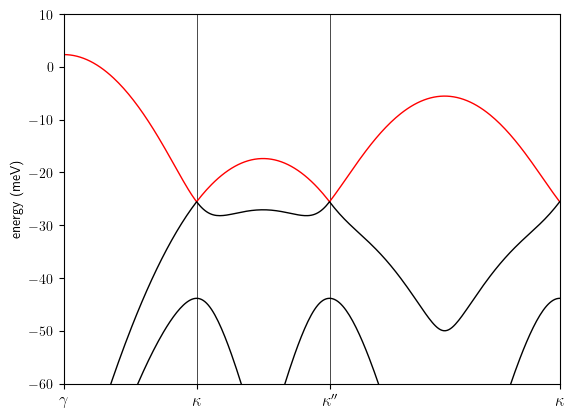

In [5]:
kpath, kdist, ticks = sys.make_k_path(*sys.default_path, n_pts=300)
bands, _ = sys.calculate_bands(kpath=kpath)

fig, ax = plt.subplots()
sys.plot_bands(ax, bands, kdist, ticks, max_bands=4)
plt.ylim([-60, 10])

### Moiré potential

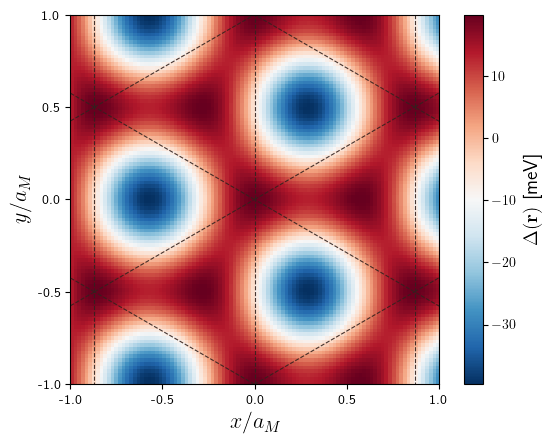

In [35]:
from matplotlib.ticker import FuncFormatter, MultipleLocator
fig, ax = plt.subplots()
scale = 1.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=100)
sys.plot_triangular_lattice(ax, extent)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(r"$\Delta(\mathbf{r})$ [meV]", fontsize=14)

aM_i = sys.aM
ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
ax.xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
ax.yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
#sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x/a_M$', fontsize=16)
ax.set_ylabel(r'$y/a_M$', fontsize=16)
plt.savefig("plots/moire_potential.pdf", dpi=300, bbox_inches='tight')

### Wannier function

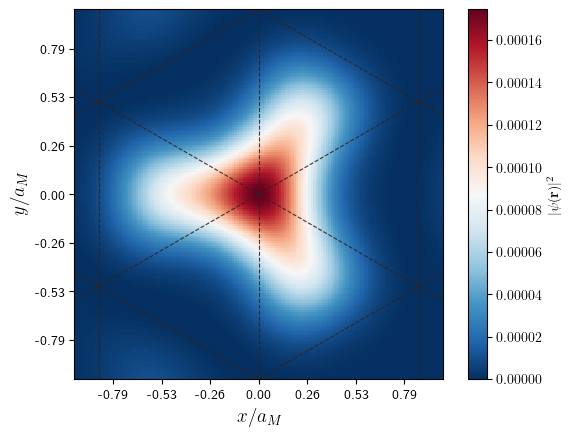

In [5]:
fig, ax = plt.subplots()
scale = 1.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
k_points = sys.mesh_k_unit_cell()
x = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
y = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
X, Y = np.meshgrid(x, y)
im = sys.plot_wannier_function(ax, X, Y, k_points)#, cmap='coolwarm')
sys.plot_triangular_lattice(ax, extent)

ax.xaxis.set_major_formatter(FuncFormatter(lambda val, pos: f'{val/sys.aM:.2f}'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, pos: f'{val/sys.aM:.2f}'))
plt.xlabel(r'$x/a_M$', fontsize=14)
plt.ylabel(r'$y/a_M$', fontsize=14)
plt.colorbar(im, ax=ax, label=r'$|\psi(\mathbf{r})|^2$', orientation='vertical');

### Berry curvature

Text(0, 0.5, '$k_y$')

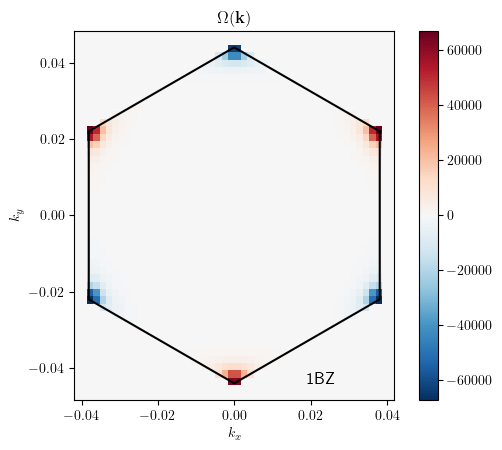

In [6]:
fig, ax = plt.subplots()
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

### Quantum metric

Text(0, 0.5, '$k_y$')

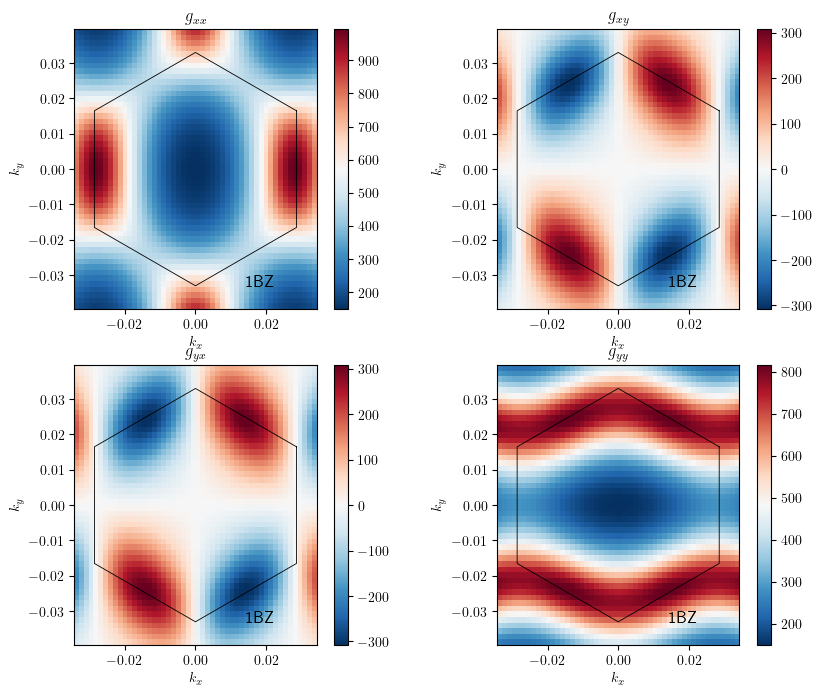

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
sys.psi_deg = 0.0
sys.theta_deg = 1.5
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric(ax, KX, KY, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

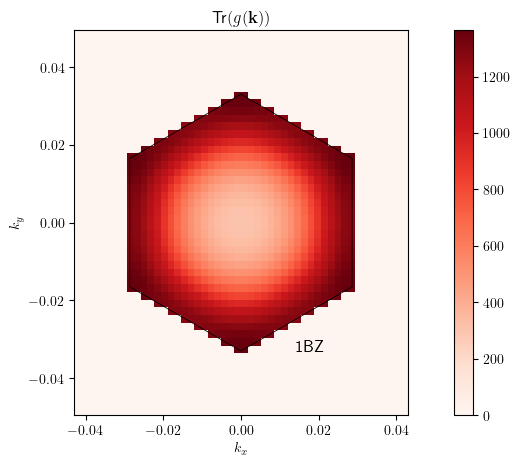

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

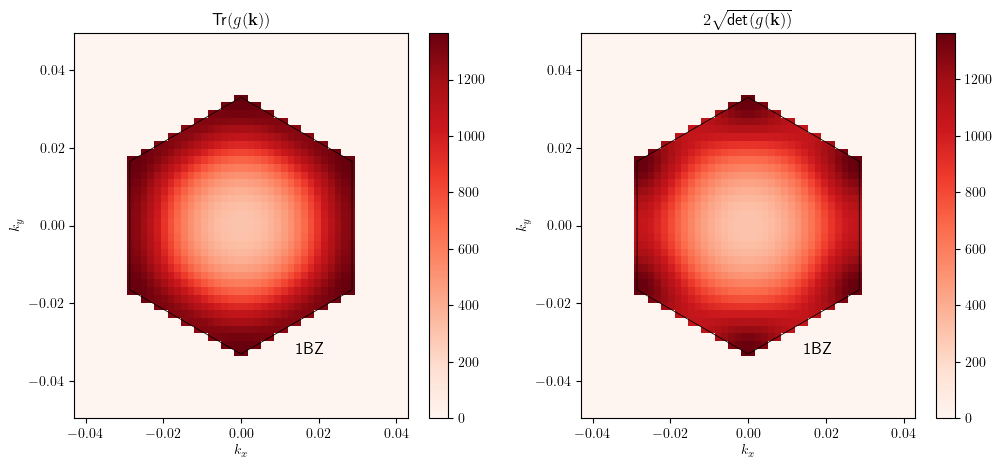

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_det_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

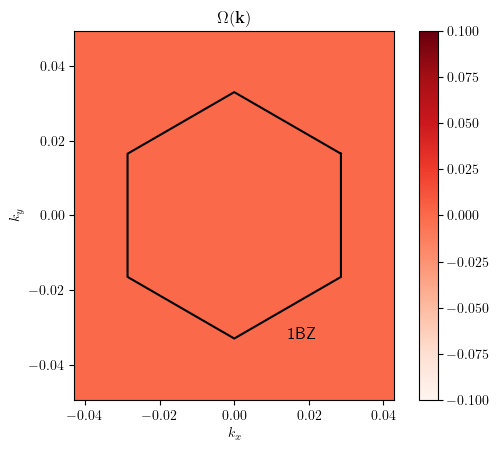

In [10]:
fig, ax = plt.subplots()
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_berry_curvature(ax, KX, KY, abs_val=True)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

Text(0, 0.5, '$k_y$')

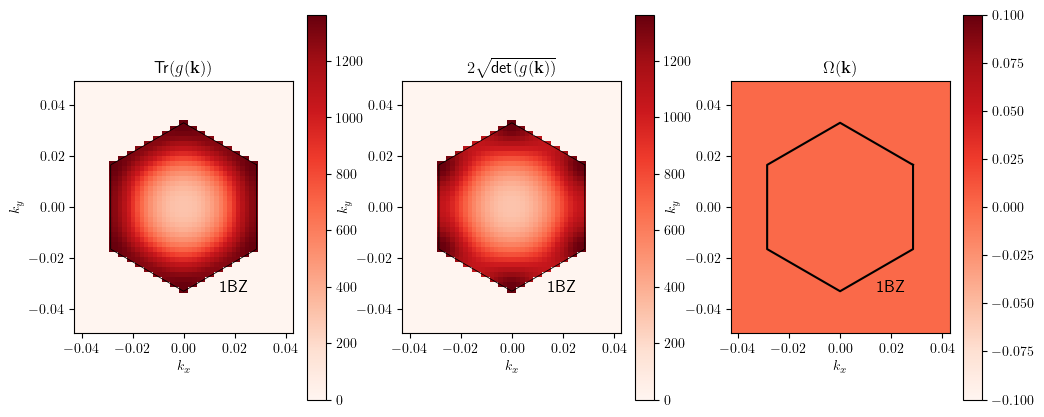

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
scale = 1.5
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric(ax[0], KX, KY)
sys.plot_det_metric(ax[1], KX, KY)
sys.plot_berry_curvature(ax[2], KX, KY, abs_val=True)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

## K-mesh

Text(0, 0.5, '$k_y$')

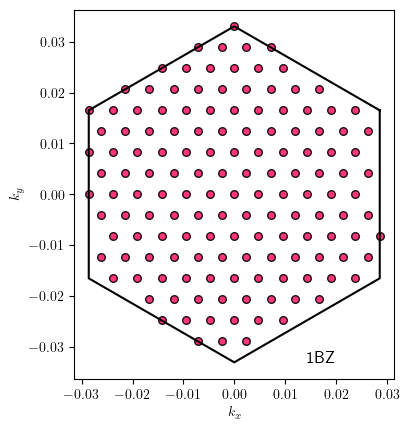

In [12]:
fig, ax = plt.subplots()
scale = 1.5
sys.plot_k_mesh(ax, Nx=12, Ny=12)

ax.set_aspect('equal')
plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

## Extra

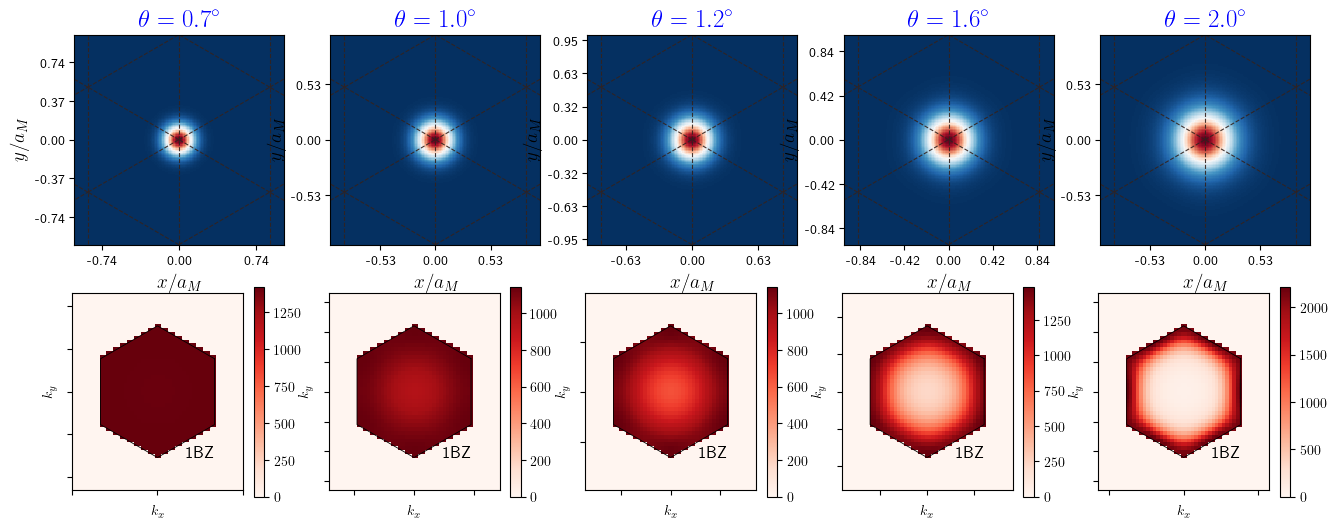

In [13]:
fig, ax = plt.subplots(2, 5, figsize=(16, 6))
scale = 1.0

thetas = [0.7, 1.0, 1.2, 1.6, 2.0]

for i, th in enumerate(thetas):
    sys.theta_deg = th
    aMi = sys.aM
    scale = 1.0

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    k_points = sys.mesh_k_unit_cell()
    x = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
    y = np.linspace(-2 * sys.aM, 2 * sys.aM, 300)
    X, Y = np.meshgrid(x, y)
    im = sys.plot_wannier_function(ax[0,i], X, Y, k_points)#, cmap='coolwarm')
    sys.plot_triangular_lattice(ax[0,i], extent)

    ax[0,i].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aMi: f'{val/L:.2f}'))
    ax[0,i].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aMi: f'{val/L:.2f}'))
    ax[0,i].set_xlabel(r'$x/a_M$', fontsize=14)
    ax[0,i].set_ylabel(r'$y/a_M$', fontsize=14)
    ax[0,i].set_title(r'$\theta = {:.1f}^\circ$'.format(th), fontsize=18, color='blue')
    #ax[0,i].colorbar(im, ax=ax, label=r'$|\psi(\mathbf{r})|^2$', orientation='vertical');

    scale = 1.5
    kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
    ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
    KX, KY = np.meshgrid(kx, ky)
    sys.plot_trace_metric(ax[1,i], KX, KY)

    ax[1,i].set_xlabel(r'$k_x$')
    ax[1,i].set_ylabel(r'$k_y$')
    ax[1,i].set_xticklabels([])
    ax[1,i].set_yticklabels([])
    ax[1,i].set_title("")

In [14]:
thetas = np.linspace(0.5, 2.0, 20)
max_list = []
min_list = []

for i, th in enumerate(thetas):
    sys.theta_deg = th
    aMi = sys.aM
    scale = 1.0
    k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)
    k_points_bz = sys.map_to_first_BZ(k_points)
    g_xx, g_xy, g_yy = sys.quantum_metric(k_points=k_points_bz)
    tr = g_xx + g_yy

    max_list.append(np.max(tr))
    min_list.append(np.min(tr))

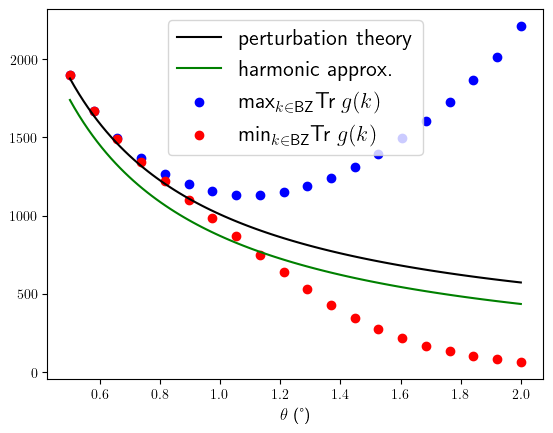

In [15]:
max_array = np.array(max_list)
min_array = np.array(min_list)

thetas2 = np.linspace(0.5, 2.0, 100)
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2) / 2))

plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi)**2, label=r'perturbation theory', color='k')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi)**2, label=r'harmonic approx.', color='g')
plt.scatter(thetas, max_array, label=r'$\text{max}_{k\in\text{BZ}} \text{Tr}\;g(k)$', color='blue')
plt.scatter(thetas, min_array, label=r'$\text{min}_{k\in\text{BZ}} \text{Tr}\;g(k)$', color='red')
plt.xlabel(r'$\theta$ (°)', fontsize=12)
plt.legend(fontsize=16)
plt.show()